In [1]:
from src.dataset_overview import load_data
import pandas as pd
from src.data_preprocessing import (
    analyze_missing_values,
    analyze_duplicates,
    analyze_outliers,
    analyze_inconsistency
)


In [2]:
# path = "../data/raw/Cardiovascular_Disease_Dataset.csv"
# target = "target"

# path = "../data/raw/dataset_regresi_dummy_110.csv"
# target = "harga_rumah_juta" 

# df_sample = load_data(file_path=path)
# df_sample.head()

In [3]:
data_kotor = {
        "ID_Pelanggan": [101, 102, 103, 103, 104, 105, 106, 107],
        "Kota": ["Jakarta", "jakarta ", "BANDUNG", "BANDUNG", "Surabaya", "surabaya", None, "Medan"],
        "Usia": [25, 30, 28, 28, -5, 42, 150, 35],          # Ada nilai negatif (-5) dan outlier (150)
        "Pendapatan": [5000, 6200, 5800, 5800, None, 7100, 95000, 6000], # Ada missing value & outlier (95000)
        "Status_Aktif": ["Ya", "ya", "Tidak", "Tidak", "YA ", None, "Tidak", "N/A"]
    }

df_sample = pd.DataFrame(data_kotor)

    # Menjalankan keempat fungsi Data Quality

,Jumlah_Kosong,Persentase (%),Tipe_Data
Kota,1,12.5,object
Pendapatan,1,12.5,float64
Status_Aktif,1,12.5,object


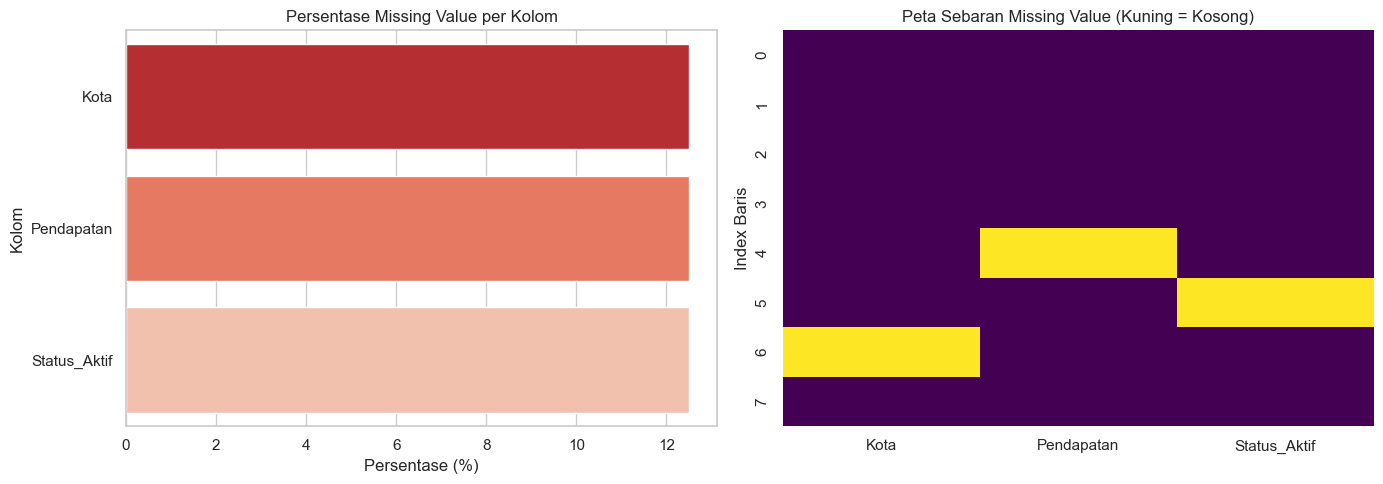

In [4]:
res_missing = analyze_missing_values(df_sample, plot=True)

Total Baris Dataset        : 8
Duplikat Persis (Full Row) : 1 baris (12.50%)

Contoh Data Duplikat (maksimal 5 baris pertama):


,ID_Pelanggan,Kota,Usia,Pendapatan,Status_Aktif
2,103,BANDUNG,28,5800.0,Tidak
3,103,BANDUNG,28,5800.0,Tidak


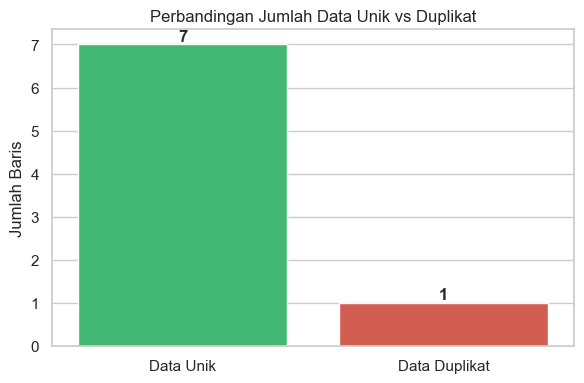

In [5]:
res_duplicates = analyze_duplicates(df_sample, plot=True)

,Batas_Bawah,Batas_Atas,Jumlah_Outlier,Persentase (%),Min_Aktual,Max_Aktual
Kolom,,,,,,
ID_Pelanggan,99.0,109.0,0,0.0,101.0,107.0
Usia,13.0,51.0,2,25.0,-5.0,150.0
Pendapatan,4525.0,7925.0,1,12.5,5000.0,95000.0


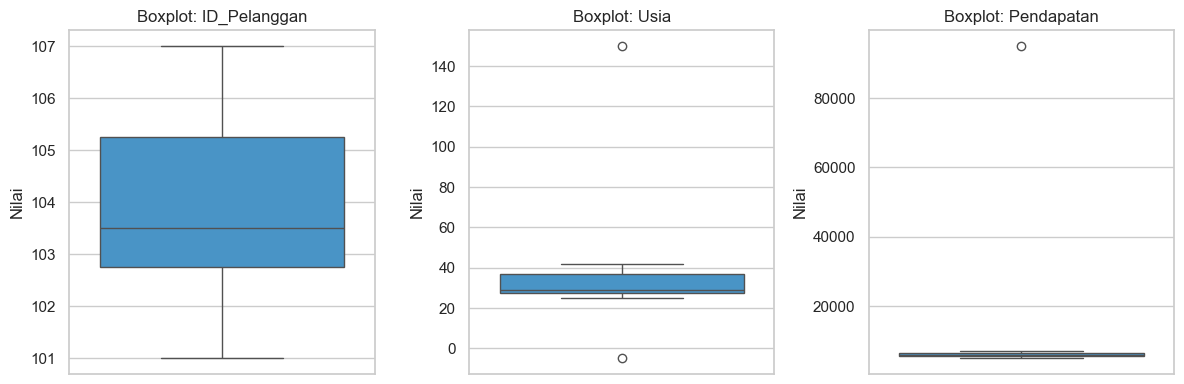

In [6]:
res_outliers = analyze_outliers(df_sample, plot=True)

In [7]:
res_inconsistency = analyze_inconsistency(df_sample)

Kolom 'Kota' (Tipe: object):
  [!] Masalah: Terdapat spasi berlebih di awal/akhir teks (leading/trailing space)
  [!] Masalah: Inkonsistensi huruf kapital (6 variasi vs 4 nilai unik)
  [-] Nilai unik (6): ['Jakarta', 'jakarta ', 'BANDUNG', 'Surabaya', 'surabaya', 'Medan']

Kolom 'Status_Aktif' (Tipe: object):
  [!] Masalah: Terdapat spasi berlebih di awal/akhir teks (leading/trailing space)
  [!] Masalah: Inkonsistensi huruf kapital (5 variasi vs 3 nilai unik)
  [-] Nilai unik (5): ['Ya', 'ya', 'Tidak', 'YA ', 'N/A']

Kolom Numerik 'Usia':
  [!] Ditemukan 1 nilai negatif (Min: -5). Periksa apakah valid.

